In [3]:
# prepairing a cnn on caltech101 with things that have been learned so far ` spidey lets get started 4:10


In [4]:
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


In [5]:
from os import stat_result
format_transform=transforms.Compose(
    [
        transforms.Resize((128,128)),
        transforms.RandomHorizontalFlip(p=0.4),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(
            brightness=0.2,
            hue=0.02,
            saturation=0.2,
            contrast=0.2
        ),
        transforms.Lambda(lambda img:img.convert('RGB')),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.4,0.4,0.4],
            std=[0.2,0.2,0.2]
        )
    ]

)

In [6]:
train_data=datasets.Caltech101(
    download=True,
    transform=format_transform,
    target_transform=None,
    root='/data'

)

100%|██████████| 137M/137M [00:00<00:00, 348MB/s] 


In [7]:
len(train_data)

8677

In [8]:
from torch.utils.data import random_split

In [9]:
total_size=len(train_data)
train_size=int(0.8*total_size)  # pass integer in the funtion  of random spilit -> torch.utils.data -> random_split
test_size=total_size-train_size


In [10]:
train_data,test_data=random_split(train_data,[train_size,test_size])  # passonlyone list in random_split

In [11]:
len(train_data) , len(test_data)

(6941, 1736)

In [12]:
train_dataloader=DataLoader(   # batch_size
    dataset=train_data,batch_size=32,shuffle=True
)
test_dataloader=DataLoader(
    dataset=test_data,batch_size=32,shuffle=True
)

In [13]:
X,y=next(iter(train_dataloader))

In [14]:
len(X)  , X[0].shape

(32, torch.Size([3, 128, 128]))

In [15]:
import matplotlib.pyplot as plt

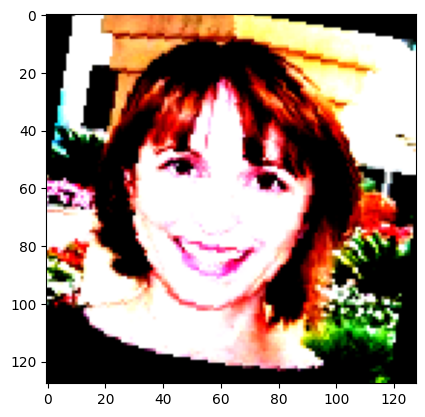

In [16]:
plt.imshow(X[23].permute(1,2,0))

In [17]:
# now data is ready time to build a model

In [18]:
from torch.nn.modules import activation
class spideyNet(nn.Module):
  def __init__(self):
    super().__init__()

    self.convlayers=nn.Sequential(
        nn.Conv2d(3,32,kernel_size=3,padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        nn.Conv2d(32,64,kernel_size=2,padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2),
        nn.Conv2d(64,128,kernel_size=2,padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.Conv2d(128,256,kernel_size=2,padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.Conv2d(256,512,kernel_size=2,padding=1),
        nn.BatchNorm2d(512),
        nn.ReLU(),
        nn.Dropout2d(p=0.2)
 )
    self.classifirelayers=nn.Sequential(
        nn.AdaptiveAvgPool2d((2,2)),
        nn.Flatten(),
        nn.Linear(512*2*2,256),
        nn.Dropout(p=0.4),
        nn.ReLU(),
        nn.Linear(256,101)
    )
  def forward(self,x):
    x=self.convlayers(x)
    x=self.classifirelayers(x)
    return x

In [19]:
device=torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

In [20]:
model1=spideyNet().to(device)

In [21]:
device

device(type='cpu')

In [22]:
model1

spideyNet(
  (convlayers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(2, 2), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(2, 2), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(128, 256, kernel_size=(2, 2), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): ReLU()
    (14): Conv2d(256,

In [23]:
loss_function=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(lr=0.001,params=model1.parameters())

In [24]:
def training_loop(model: torch.nn.Module,
                  loss_function: torch.nn.Module,
                  optimizer: torch.optim.Optimizer,
                  dataloader: torch.utils.data.DataLoader,
                  device: torch.device,
                  epoch: int):
  model.train()
  train_loss = 0
  correct = 0
  total = 0
  for batch, (X, y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)
    y_pred = model(X)
    loss = loss_function(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += loss.item()
    _, predicted = y_pred.max(1)
    total += y.size(0)
    correct += predicted.eq(y).sum().item()

  train_loss /= len(dataloader)
  acc = 100. * correct / total
  print(f'Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Train Acc: {acc:.2f}%')

In [25]:
def testing_loop(model: torch.nn.Module,
                 loss_function: torch.nn.Module,
                 dataloader: torch.utils.data.DataLoader,
                 device: torch.device,
                 epoch: int):
  model.eval()
  test_loss = 0
  correct = 0
  total = 0
  with torch.inference_mode():
    for X, y in dataloader:
      X, y = X.to(device), y.to(device)
      y_pred = model(X)
      loss = loss_function(y_pred, y)

      test_loss += loss.item()
      _, predicted = y_pred.max(1)
      total += y.size(0)
      correct += predicted.eq(y).sum().item()

  test_loss /= len(dataloader)
  acc = 100. * correct / total
  print(f'Epoch {epoch+1} | Test Loss: {test_loss:.4f} | Test Acc: {acc:.2f}%\n' + '-'*40)

In [26]:
import tqdm.auto as tqdm

In [ ]:
epochs = 10
for epoch in range(epochs):
  training_loop(
      model=model1,
      loss_function=loss_function,
      optimizer=optimizer,
      dataloader=train_dataloader,
      device=device,
      epoch=epoch
  )
  testing_loop(
      model=model1,
      loss_function=loss_function,
      dataloader=test_dataloader,
      device=device,
      epoch=epoch
  )